In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../generated_data/subjects_AND_sampling_metadata.csv", parse_dates=["created_at"])

C:\Users\yuyue\AppData\Local\Temp\ipykernel_53152\3142735918.py:4: DtypeWarning: Columns (3,14,15,16,17,18,26,27,28,29,39,41,42,46,48,49,70,71,72,73,75,76,77,78,79) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../generated_data/subjects_AND_sampling_metadata.csv", parse_dates=["created_at"])


In [2]:
# Sample about 15% of users, stratified by demographics

p_users = 0.15
np.random.seed(42) 

strata_vars = [
    "gpt_QUOTA_ETHNICITY",
    "gpt_QUOTA_AGE",
    "gpt_QUOTA_SEX",
    "gpt_QUOTA_HIGHEST EDUCATIONAL QUALIFICATION"
]

users_unique = df.drop_duplicates(subset=["id"]).copy()

users_unique["strata"] = users_unique[strata_vars].astype(str).agg("||".join, axis=1)

sampled_users = (
    users_unique.groupby("strata", group_keys=False)
    .apply(lambda x: x.sample(max(1, int(np.floor(p_users * len(x))))))
    .reset_index(drop=True)
)

sampled_user_ids = set(sampled_users["id"])

C:\Users\yuyue\AppData\Local\Temp\ipykernel_37944\499376572.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(max(1, int(np.floor(p_users * len(x))))))


In [3]:
len(sampled_user_ids)

155

In [4]:
tweets_df = df[df["id"].isin(sampled_user_ids)].copy()

In [5]:
tweets_df

,gpt_id,id,created_at.users,description,location,protected,verified_type,username,public_metrics.followers_count,public_metrics.following_count,...,gpt_speculation_QUOTA_PAYING ATTENTION TO THE 2024 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PARTISAN LOYALTIES,"gpt_speculation_QUOTA_IDEOLOGICALLY, THIS PERSON APPEARS TO BE",gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple
62675,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62676,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62677,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62678,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62679,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144643,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
2144644,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
2144645,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
2144646,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA


In [6]:
#validating the distribution of the demographic characeteristic in the sample drawed
def compare_distributions(df_full, df_sample, vars_to_check):
    for var in vars_to_check:
        print(f"\n--- {var} ---")
        
        full_counts = df_full[var].value_counts(dropna=False)
        full_pct = full_counts / len(df_full) * 100
        
        sample_counts = df_sample[var].value_counts(dropna=False)
        sample_pct = sample_counts / len(df_sample) * 100
        
        comparison = pd.DataFrame({
            "full_count": full_counts,
            "full_pct": full_pct.round(2),
            "sample_count": sample_counts,
            "sample_pct": sample_pct.round(2)
        }).fillna(0)
        
        print(comparison)

compare_distributions(
    df_full=df.drop_duplicates(subset=["id"]),        
    df_sample=sampled_users,                         
    vars_to_check=strata_vars                        
)



--- gpt_QUOTA_ETHNICITY ---
                                                    full_count  full_pct  \
gpt_QUOTA_ETHNICITY                                                        
white - individuals with origins in any of the ...         802     86.42   
black or african american - individuals with or...          71      7.65   
hispanic or latino - includes individuals of me...          38      4.09   
asian - individuals with origins in any of the ...          10      1.08   
multiracial - individuals who identify explicit...           7      0.75   

                                                    sample_count  sample_pct  
gpt_QUOTA_ETHNICITY                                                           
white - individuals with origins in any of the ...           112       72.26  
black or african american - individuals with or...            17       10.97  
hispanic or latino - includes individuals of me...            14        9.03  
asian - individuals with origins in any of 

In [7]:
from collections import Counter
import pandas as pd
from datetime import datetime

# Define pre-election period
election_date = pd.Timestamp("2024-11-05", tz="UTC")
start_period = election_date - pd.DateOffset(years=1)
end_period = election_date
df_pre_election = tweets_df[(tweets_df["created_at"] >= start_period) & (tweets_df["created_at"] <= end_period)].copy()


In [9]:
df_pre_election

,gpt_id,id,created_at.users,description,location,protected,verified_type,username,public_metrics.followers_count,public_metrics.following_count,...,gpt_speculation_QUOTA_PAYING ATTENTION TO THE 2024 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PARTISAN LOYALTIES,"gpt_speculation_QUOTA_IDEOLOGICALLY, THIS PERSON APPEARS TO BE",gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple
62675,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62676,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62677,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62678,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
62679,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144643,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
2144644,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
2144645,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
2144646,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA


In [ ]:
df_pre_election.to_csv("../generated_data/timebin_identification/timebin_identification_sample.csv")

In [22]:
df_target = pd.read_csv("../generated_data/timebin_identification/timebin_identification_sample.csv").drop(columns=["Unnamed: 0"])

C:\Users\yuyue\AppData\Local\Temp\ipykernel_11480\2066691176.py:1: DtypeWarning: Columns (15,16,17,18,19,27,30,42,49,50,71,72,74,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  df_target = pd.read_csv("../generated_data/timebin_identification/timebin_identification_sample.csv").drop(columns=["Unnamed: 0"])


In [24]:
df_target

,gpt_id,id,created_at.users,description,location,protected,verified_type,username,public_metrics.followers_count,public_metrics.following_count,...,gpt_speculation_QUOTA_PAYING ATTENTION TO THE 2024 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PARTISAN LOYALTIES,"gpt_speculation_QUOTA_IDEOLOGICALLY, THIS PERSON APPEARS TO BE",gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple
0,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
1,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
2,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
3,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
4,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,20,10,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277871,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
277872,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
277873,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA
277874,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,60,65,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA


In [23]:
import pandas as pd

df_with_desc = pd.read_csv("../generated_data/final_user_profiles_cleaned.csv")  

# Merge on "id", keeping all rows from df_target
merged_df = df_target.merge(
    df_with_desc[["id", "profile_image_url", "profile_image_description", "profile_image_main_info"]],
    on="id",
    how="left",
    suffixes=("", "_new")  
)

# Overwrite profile_image_url with the new value (only where not null)
merged_df["profile_image_url"] = merged_df["profile_image_url_new"].combine_first(merged_df["profile_image_url"])

# Drop the temporary column used for overwrite
merged_df = merged_df.drop(columns=["profile_image_url_new"])

merged_df.to_csv("../generated_data/timebin_identification/new_timebin_identification_sample.csv", index=False)
print("Merged dataframe saved")


Merged dataframe saved


In [25]:
merged_df

,gpt_id,id,created_at.users,description,location,protected,verified_type,username,public_metrics.followers_count,public_metrics.following_count,...,"gpt_speculation_QUOTA_IDEOLOGICALLY, THIS PERSON APPEARS TO BE",gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple,profile_image_description,profile_image_main_info
0,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana,### 1. Visible Physical Characteristics:\n- Th...,### 1. Visible Physical Characteristics:\n- Th...
1,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana,### 1. Visible Physical Characteristics:\n- Th...,### 1. Visible Physical Characteristics:\n- Th...
2,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana,### 1. Visible Physical Characteristics:\n- Th...,### 1. Visible Physical Characteristics:\n- Th...
3,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana,### 1. Visible Physical Characteristics:\n- Th...,### 1. Visible Physical Characteristics:\n- Th...
4,079f22ee85ae1d60084d28f1154ca0ee28b6757d406d40...,1715552550806749184,2023-10-21T02:16:28.000Z,"Strong Christian morals and values, with conse...",Montana,False,none,Delam46,151,39,...,10,30.0,30,20,20,race,2024-10-15T05:32:12Z,Montana,### 1. Visible Physical Characteristics:\n- Th...,### 1. Visible Physical Characteristics:\n- Th...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277871,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA,The image is a cartoon illustration of Betty B...,The image is a cartoon illustration of Betty B...
277872,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA,The image is a cartoon illustration of Betty B...,The image is a cartoon illustration of Betty B...
277873,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA,The image is a cartoon illustration of Betty B...,The image is a cartoon illustration of Betty B...
277874,fe446ad4178e9118f4c1b3db6556f2be127b4e8d88302f...,90123499,2009-11-15T08:09:19.000Z,Dulsura por mi Mami de San Juan Puerto Rico Fu...,USA,False,none,dulcebombomcito,1420,1216,...,75,80.0,80,85,85,crime,2024-10-15T05:17:33Z,USA,The image is a cartoon illustration of Betty B...,The image is a cartoon illustration of Betty B...


In [26]:
def sample_non_overlapping_windows_global(df, user_col, time_col, window_days, k, global_start, global_end, random_state=None):
    rng = np.random.default_rng(random_state)
    
    df = df.copy()
    df[time_col] = pd.to_datetime(df[time_col], utc=True)

    possible_starts = pd.date_range(
        start=global_start.normalize(),
        end=global_end - pd.Timedelta(days=window_days - 1),
        freq="D"
    ).to_pydatetime().tolist()

    all_windows = []

    for uid in df[user_col].unique():
        user_possible_starts = possible_starts.copy()
        sampled_windows = []

        while len(sampled_windows) < k and user_possible_starts:
            start_candidate = rng.choice(user_possible_starts)
            candidate_end = start_candidate + pd.Timedelta(days=window_days - 1)
            sampled_windows.append((uid, start_candidate, candidate_end))

            # Remove overlapping candidates for this user
            user_possible_starts = [
                d for d in user_possible_starts
                if (d + pd.Timedelta(days=window_days - 1) < start_candidate) or (d > candidate_end)
            ]

        if len(sampled_windows) < k:
            print(f"User {uid} only got {len(sampled_windows)} windows sampled (requested {k}).")

        all_windows.extend(sampled_windows)

    windows_df = pd.DataFrame(all_windows, columns=[user_col, "window_start", "window_end"])

    merged_df = windows_df.merge(df, on=user_col, how="left")

    merged_df["in_window"] = (
        (merged_df[time_col] >= merged_df["window_start"]) &
        (merged_df[time_col] <= merged_df["window_end"])
    )
    def fill_empty_windows(group):
        if group["in_window"].any():
            result = group[group["in_window"]].copy()
            result["is_empty_window"] = False  
            return result
        else:
            empty_row = group.iloc[[0]].copy()

            for col in ["tweets_historical", time_col]:
                if col in empty_row.columns:
                    empty_row[col] = pd.NA if col != time_col else pd.NaT

            empty_row["in_window"] = False
            empty_row["is_empty_window"] = True  
            return empty_row


    merged_df = merged_df.groupby([user_col, "window_start", "window_end"], as_index=False, group_keys=False).apply(fill_empty_windows)

    

    return merged_df, windows_df


In [17]:
import pandas as pd
import numpy as np

In [37]:
df_pre_election = pd.read_csv("../generated_data/timebin_identification/new_timebin_identification_sample.csv")

C:\Users\yuyue\AppData\Local\Temp\ipykernel_11480\912409585.py:1: DtypeWarning: Columns (14,15,16,17,18,26,29,41,48,49,70,71,73,75,76,77) have mixed types. Specify dtype option on import or set low_memory=False.
  df_pre_election = pd.read_csv("../generated_data/timebin_identification/new_timebin_identification_sample.csv")


In [69]:
global_end = pd.Timestamp("2024-11-05", tz="UTC")
global_start = global_end - pd.DateOffset(years=1)
merged_df, windows_df = sample_non_overlapping_windows_global(
    df = df_pre_election,
    user_col="id",
    time_col="created_at",
    window_days=120,
    k=4,
    global_start=global_start,
    global_end=global_end,
    random_state=42,
)

User 1715552550806749184 only got 2 windows sampled (requested 4).
User 1157713275355721728 only got 2 windows sampled (requested 4).
User 1738011743622922240 only got 2 windows sampled (requested 4).
User 1023271775415820289 only got 2 windows sampled (requested 4).
User 545445165 only got 2 windows sampled (requested 4).
User 1453914509786193923 only got 2 windows sampled (requested 4).
User 143631813 only got 2 windows sampled (requested 4).
User 1469868428207050752 only got 2 windows sampled (requested 4).
User 24577679 only got 3 windows sampled (requested 4).
User 1456460903382228992 only got 2 windows sampled (requested 4).
User 599083898 only got 3 windows sampled (requested 4).
User 1467760462540410891 only got 2 windows sampled (requested 4).
User 15449744 only got 2 windows sampled (requested 4).
User 73369826 only got 2 windows sampled (requested 4).
User 1553777455 only got 2 windows sampled (requested 4).
User 12695752 only got 2 windows sampled (requested 4).
User 159140

C:\Users\yuyue\AppData\Local\Temp\ipykernel_11480\3281742946.py:60: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  merged_df = merged_df.groupby([user_col, "window_start", "window_end"], as_index=False, group_keys=False).apply(fill_empty_windows)


In [70]:
merged_df

,id,window_start,window_end,gpt_id,created_at.users,description,location,protected,verified_type,username,...,gpt_speculation_QUOTA_PAST VOTE - TURNOUT IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2020 PRESIDENTIAL ELECTION,gpt_speculation_QUOTA_PAST VOTE - VOTE CHOICE IN THE 2022 HOUSE OF REPRESENTATIVES ELECTION,clean...pool,clean...pool.date,clean...state_simple,profile_image_description,profile_image_main_info,in_window,is_empty_window
53747,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,60,90,90,trad,2024-10-28T04:52:01Z,California,### Analysis of the Profile Image\n\n#### 1. V...,### Analysis of the Profile Image\n\n#### 1. V...,True,False
53748,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,60,90,90,trad,2024-10-28T04:52:01Z,California,### Analysis of the Profile Image\n\n#### 1. V...,### Analysis of the Profile Image\n\n#### 1. V...,True,False
53749,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,60,90,90,trad,2024-10-28T04:52:01Z,California,### Analysis of the Profile Image\n\n#### 1. V...,### Analysis of the Profile Image\n\n#### 1. V...,True,False
53750,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,60,90,90,trad,2024-10-28T04:52:01Z,California,### Analysis of the Profile Image\n\n#### 1. V...,### Analysis of the Profile Image\n\n#### 1. V...,True,False
53751,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,1f0dd719b37defb1e8184ffdd81cbc9cf6320d90a99451...,2008-01-25T20:19:58.000Z,Dantooine. They're on Dantooine.,Silicon Valley,False,none,dcurtisj,...,60,90,90,trad,2024-10-28T04:52:01Z,California,### Analysis of the Profile Image\n\n#### 1. V...,### Analysis of the Profile Image\n\n#### 1. V...,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547969,1834689413168672768,2023-11-07 00:00:00+00:00,2024-03-05 00:00:00+00:00,f009738789d6cc21af1548abc6fe3ba0bfa2662f900cd0...,2024-09-13T20:23:52.000Z,Actively seeking passive income | Proud TIA Pr...,Torrance,False,none,TiffanySco83644,...,80,85,85,immigration,2024-10-28T04:48:31Z,California,The image is an anime-style illustration of a ...,The image is an anime-style illustration of a ...,False,True
547979,1834689413168672768,2024-06-26 00:00:00+00:00,2024-10-23 00:00:00+00:00,f009738789d6cc21af1548abc6fe3ba0bfa2662f900cd0...,2024-09-13T20:23:52.000Z,Actively seeking passive income | Proud TIA Pr...,Torrance,False,none,TiffanySco83644,...,80,85,85,immigration,2024-10-28T04:48:31Z,California,The image is an anime-style illustration of a ...,The image is an anime-style illustration of a ...,True,False
547980,1834689413168672768,2024-06-26 00:00:00+00:00,2024-10-23 00:00:00+00:00,f009738789d6cc21af1548abc6fe3ba0bfa2662f900cd0...,2024-09-13T20:23:52.000Z,Actively seeking passive income | Proud TIA Pr...,Torrance,False,none,TiffanySco83644,...,80,85,85,immigration,2024-10-28T04:48:31Z,California,The image is an anime-style illustration of a ...,The image is an anime-style illustration of a ...,True,False
462011,1839135745908305920,2023-11-23 00:00:00+00:00,2024-03-21 00:00:00+00:00,ceb7343944dc0fe98c9abea2841b14bd4df3d5b00aaf01...,2024-09-26T02:51:46.000Z,Foodie,USA,False,none,highway_vessel,...,60,50,60,democracy,2024-09-29T08:58:25Z,USA,**1. Visible Physical Characteristics:**\n\n* ...,**1. Visible Physical Characteristics:**\n\n* 

In [71]:
merged_df.to_csv("../generated_data/timebin_identification/120days_window/120days_timebin_sample_df.csv", index=False, encoding="utf-8-sig")

In [72]:
import matplotlib.pyplot as plt

num_users = merged_df["id"].nunique()
print(f"Number of unique users sampled: {num_users}")

num_windows = merged_df.groupby(["id", "window_start"]).ngroups
print(f"Number of sampled windows: {num_windows}")

avg_tweets_per_window = merged_df.groupby(["id", "window_start"]).size().mean()
print(f"Average number of tweets per window: {avg_tweets_per_window:.2f}")


Number of unique users sampled: 155
Number of sampled windows: 315
Average number of tweets per window: 578.59


In [73]:
total_windows = merged_df[["id", "window_start", "window_end"]].drop_duplicates().shape[0]
window_counts = merged_df.groupby(["id", "window_start", "window_end"])["in_window"].sum()
empty_windows = (window_counts == 0).sum()

print(f"Empty windows: {empty_windows} ({empty_windows / total_windows:.1%})")


Empty windows: 113 (35.9%)


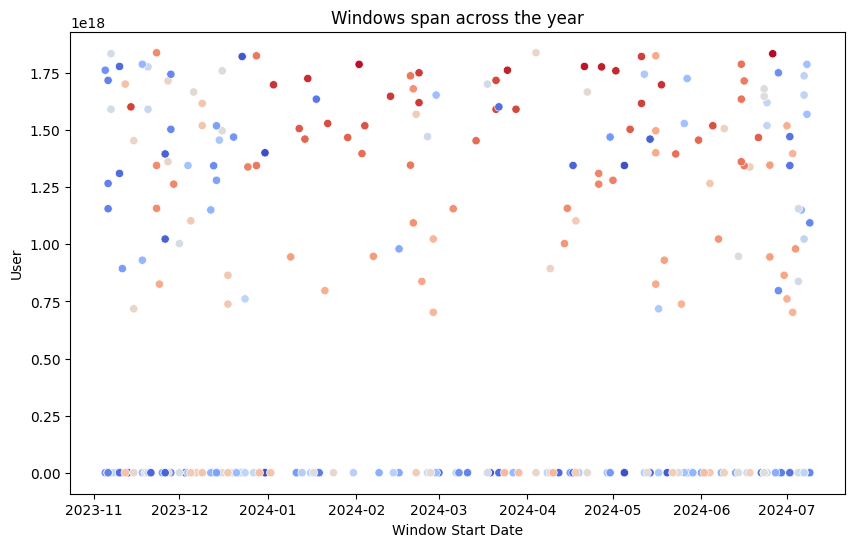

In [74]:
import seaborn as sns

# Drop duplicates so each window is counted once
unique_windows = merged_df[["id", "window_start", "window_end"]].drop_duplicates()

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=unique_windows,
    x="window_start", 
    y="id", 
    hue="window_end", 
    palette="coolwarm",
    legend=False 
)
plt.title("Windows span across the year")
plt.xlabel("Window Start Date")
plt.ylabel("User")
plt.show()
